In [ ]:
import numpy as np                          # cuentas con vectores y matrices
from scipy.integrate import solve_ivp      # resuelve ecuaciones diferenciales
import matplotlib.pyplot as plt
import random

#################################################################
############  simular

def condiciones_iniciales_random(n, semilla=None):
    # Devuelve n fases al azar, uniformes entre 0 y 2*pi.
    rng = np.random.default_rng(semilla)    # generador de números aleatorios
    return rng.uniform(-np.pi, np.pi, n)


def potencial(phi, A, K, Delta):
    # V = sum_i (1/d) sum_{j vecino de i} (1/2) K_ji (1 - cos(phi_j - phi_i - Delta_ji))
    n = len(phi)                            # cantidad de nodos
    d = 4                          # grado (es el mismo para todos)
    V = 0.0                                 # acumulador
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # pero solo suma si j es vecino de i
                V += (1 / d) * 0.5 * K[j, i] * (1 - np.cos(phi[j] - phi[i] - Delta[j, i]))
    return V


def ecuaciones(t, phi, A, K, Delta, omega=0.0):
    # dphi_i/dt = omega - dV/dphi_i
    #           = omega + (1/d) sum_{j vecino de i} [ (K_ji/2) sin(phi_j - phi_i - Delta_ji)
    #                                                + (K_ij/2) sin(phi_j - phi_i + Delta_ij) ]
    # (t no se usa, pero solve_ivp lo pide como primer argumento)
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado
    dphi = np.full(n, omega)                # empieza con la frecuencia natural
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # solo los vecinos aportan
                dphi[i] += (1 / d) * 0.5 * K[j, i] * np.sin(phi[j] - phi[i] - Delta[j, i])
                dphi[i] += (1 / d) * 0.5 * K[i, j] * np.sin(phi[j] - phi[i] + Delta[i, j])
    return dphi


def simular(phi0, A, K, Delta, T, omega=0.0):
    # Integra las ecuaciones desde t=0 hasta t=T partiendo de phi0.
    sol = solve_ivp(ecuaciones, (0, T), phi0, args=(A, K, Delta, omega),
                    rtol=1e-8, atol=1e-10)  # tolerancias chicas = más precisión
    return sol.t, sol.y                     # tiempos y fases (sol.y[i] es la fase del nodo i)

############################################################################################
################# matrices importantes

def matriz_ady(n):
      A = np.full((n,n), 0)
      for i in range(n-1):
        A[i,i+1] = 1
        A[i+1,i] = 1
      return A

def matriz_flow_uni(n):
      K = np.full((n,n), 0)
      for i in range(n-1):
        K[i,i+1] = 1
      return K

def matriz_flow_bi(n):
      K = np.full((n,n), 0)
      for i in range(n-1):
        K[i,i+1] = 1
        K[i+1,i] = 1
      return K

def matriz_K1(n, av, perp, primera_sube=True):
  # n = cruces por calle (columnas); filas: 0 = calle de arriba, 1 = doble mano, 2 = calle de abajo
  m = 3 * n
  K = np.zeros((m, m))                           # float: si no, perp = 0.8 se trunca a 0

  for i in range(n - 1):
    K[i, i + 1] = av                             # arriba: solo hacia la derecha (i -> i+1)
    K[n + i, n + i + 1] = av                     # medio: doble mano, hacia la derecha...
    K[n + i + 1, n + i] = av                     # ...y hacia la izquierda
    K[2*n + i + 1, 2*n + i] = av                 # abajo: solo hacia la izquierda (i+1 -> i)

  for i in range(n):                             # perpendiculares: sentidos alternados
    sube = (i % 2 == 0) == primera_sube          # con primera_sube=True, la columna 0 sube
    if sube:
      K[2*n + i, n + i] = perp                   # fila de abajo -> fila del medio
      K[n + i, i] = perp                         # fila del medio -> fila de arriba
    else:
      K[i, n + i] = perp                         # fila de arriba -> fila del medio
      K[n + i, 2*n + i] = perp                   # fila del medio -> fila de abajo
  return K

def matriz_ady1(n, calles=3):
  # n = cruces por calle (columnas), calles = calles paralelas (filas)
  m = calles * n                        # cantidad total de semáforos
  A = np.zeros((m, m), dtype=int)

  for c in range(calles):               # cada calle paralela
    for i in range(n):                  # cada cruce de esa calle
      k = c * n + i                     # índice del semáforo (calle c, cruce i)
      if i + 1 < n:                     # vecino siguiente sobre la misma calle
        A[k, k + 1] = 1
        A[k + 1, k] = 1
      if c + 1 < calles:                # vecino de la calle de abajo (perpendicular)
        A[k, k + n] = 1
        A[k + n, k] = 1
  return A


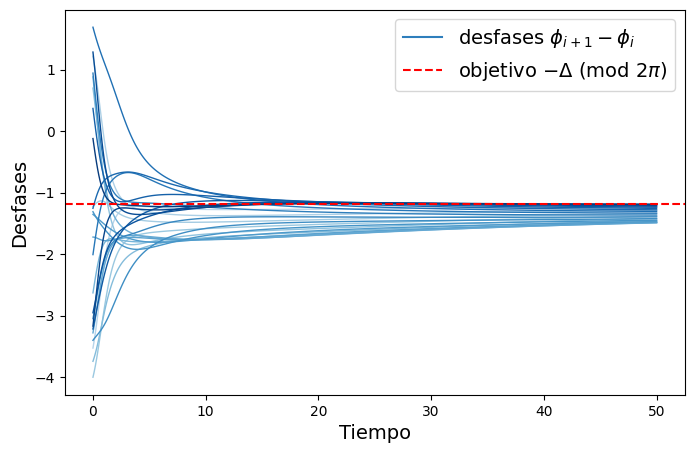

fases iniciales: [ 0.07427746  2.83034688 -2.23581109  2.81894761 -1.18229786 -0.48175413
  2.05901612 -0.57051865  0.31160633 -2.96843364  1.59286984  0.23966151
 -1.06982718  1.81225099 -1.23656336 -0.29218138 -2.29938383 -0.60875906
 -1.86324567 -1.49342933  1.57308763 -1.37973247 -0.09304785  3.02056091
  2.9006777 ]
Potencial inicial: 13.299367817409397
Potencial final:   0.2362473949749399
Delta = 0π/8 | V inicial = 3.475 | V final = 0.000
Delta = 1π/8 | V inicial = 3.515 | V final = 0.304
Delta = 2π/8 | V inicial = 4.807 | V final = 1.172
Delta = 3π/8 | V inicial = 3.957 | V final = 2.469
Delta = 5π/8 | V inicial = 4.201 | V final = 2.469
Delta = 6π/8 | V inicial = 3.366 | V final = 1.172
Delta = 7π/8 | V inicial = 2.953 | V final = 0.304
Delta = 8π/8 | V inicial = 1.920 | V final = 0.000


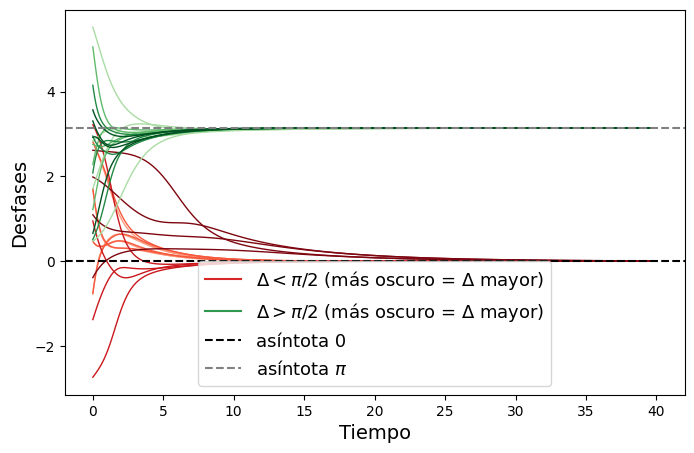

In [ ]:
def normalizar(d, centro=0.0):
    # corre la curva d un múltiplo de 2*pi para que su valor final quede lo más cerca posible de `centro`
    return d - 2*np.pi*np.round((d[-1] - centro) / (2*np.pi))


# ------------------------------- Calle recta, un solo sentido -------------------------------

n = 25
T = 50

A = matriz_ady(n)
K = matriz_flow_uni(n)
Delta = np.full((n, n), 3 * np.pi / 8)                      # todos los desfases iguales

phi0 = condiciones_iniciales_random(n, semilla=random.randint(1, 10))   # fases iniciales al azar
t, phi = simular(phi0, A, K, Delta, T)
phi_final = phi[:, -1]

objetivo = -Delta[0, 0]                                     # en un sentido: phi_{i+1} - phi_i = -Delta
tonos = np.linspace(0.3, 0.95, n - 1)                       # claro -> oscuro en el sentido de circulación

plt.figure(figsize=(8, 5))
for i, tono in enumerate(tonos):
    plt.plot(t, normalizar(phi[i+1] - phi[i], objetivo), color=plt.cm.Blues(tono), lw=1)
plt.plot([], [], color=plt.cm.Blues(0.7), label=r'desfases $\phi_{i+1}-\phi_i$')
plt.axhline(objetivo, linestyle='--', color='red', label=r'objetivo $-\Delta$ (mod $2\pi$)')
plt.legend(fontsize = 14)
plt.xlabel('Tiempo', fontsize = 14)
plt.ylabel('Desfases', fontsize = 14)
plt.show()

print('fases iniciales:', phi0)
print('Potencial inicial:', potencial(phi0, A, K, Delta))
print('Potencial final:  ', potencial(phi_final, A, K, Delta))


# ------------------------------- Calle recta, ambos sentidos -------------------------------

n = 5
T = 40

A = matriz_ady(n)
K = matriz_flow_bi(n)

# (nombre, colores, valor al que convergen, múltiplos de pi/8 para Delta)
grupos = [(r'$\Delta<\pi/2$', plt.cm.Reds,   0.0,   [0, 1, 2, 3]),
          (r'$\Delta>\pi/2$', plt.cm.Greens, np.pi, [5, 6, 7, 8])]

plt.figure(figsize=(8, 5))
for nombre, cmap, centro, multiplos in grupos:
    tonos = np.linspace(0.35, 0.95, len(multiplos))         # más oscuro = Delta más grande
    for j, tono in zip(multiplos, tonos):
        Delta = np.full((n, n), j * np.pi / 8)
        phi0 = condiciones_iniciales_random(n, semilla=random.randint(1, 10))
        t, phi = simular(phi0, A, K, Delta, T)
        for i in range(n - 1):
            plt.plot(t, normalizar(phi[i+1] - phi[i], centro), color=cmap(tono), lw=1)
        print(f'Delta = {j}π/8 | V inicial = {potencial(phi0, A, K, Delta):.3f} | V final = {potencial(phi[:, -1], A, K, Delta):.3f}')
    plt.plot([], [], color=cmap(0.7), label=nombre + ' (más oscuro = Δ mayor)')

plt.axhline(0,     linestyle='--', color='black', label='asíntota 0')
plt.axhline(np.pi, linestyle='--', color='gray',  label=r'asíntota $\pi$')
plt.legend(fontsize = 13)
plt.xlabel('Tiempo', fontsize = 14)
plt.ylabel('Desfases', fontsize = 14)
plt.show()

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp

# --- avenida + perpendiculares + paralelas---

# --- Parámetros fijos ---
m_zero = 10
n_zero = 3 * m_zero
N_CI_zero = 50
T_MAX_zero = 300
K_AV_zero = 10.0

# --- Matrices básicas aisladas ---
A_zero = matriz_ady1(m_zero)
Delta_zero = np.full((n_zero, n_zero), 2 * np.pi / 8)
# Fuerza bruta: K_perp = 0
K_zero = matriz_K1(m_zero, K_AV_zero, 0.0)

lista_V0 = []
lista_Vfin = []
fallos = 0

# --- Funciones matemáticas aisladas ---
def V_aislado(phi):
    D = phi[None, :] - phi[:, None]
    d = A_zero[0].sum()
    return (A_zero * 0.5 * K_zero.T * (1 - np.cos(D - Delta_zero.T))).sum() / d

def rhs_aislado(t, phi):
    D = phi[None, :] - phi[:, None]
    d = A_zero[0].sum()
    return (A_zero * (0.5 * K_zero.T * np.sin(D - Delta_zero.T) +
                      0.5 * K_zero * np.sin(D + Delta_zero))).sum(axis=1) / d

def convergio_aislado(t, phi):
    return np.abs(rhs_aislado(t, phi)).max() - 1e-6
convergio_aislado.terminal = True

print("Iniciando corrida para K=0...")

# --- Simulación ---
for b in range(N_CI_zero):
    phi0 = condiciones_iniciales_random(n_zero, semilla=b)

    # Potencial inicial
    lista_V0.append(V_aislado(phi0))

    # Ecuación diferencial
    sol = solve_ivp(rhs_aislado, (0, T_MAX_zero), phi0,
                    events=convergio_aislado, rtol=1e-8, atol=1e-10)

    # Potencial final
    phi_f = sol.y[:, -1]
    lista_Vfin.append(V_aislado(phi_f))

    fallos += (sol.status != 1)

print(f"Fallos de convergencia: {fallos}")
print("\n--- Copia esto ---")
print(f"V0_K0 = {lista_V0}")
print(f"Vfin_K0 = {lista_Vfin}")

Iniciando corrida para K=0...
Fallos de convergencia: 0

--- Copia esto ---
V0_K0 = [np.float64(46.23214971653741), np.float64(65.82272620831122), np.float64(81.89692989693481), np.float64(75.30324800569043), np.float64(83.07925120682593), np.float64(61.14366023858216), np.float64(65.66675383613581), np.float64(57.91680535261498), np.float64(59.79882735071091), np.float64(67.36090569759274), np.float64(84.60803182895249), np.float64(62.0437129549488), np.float64(62.6169967721474), np.float64(75.50975763640794), np.float64(73.43134160119482), np.float64(75.62574979415615), np.float64(74.71398682121435), np.float64(73.68610909104015), np.float64(54.36725466828384), np.float64(67.76491526255703), np.float64(45.710212002212714), np.float64(70.1887124308899), np.float64(61.842521077272075), np.float64(63.616544723941644), np.float64(60.64079506342752), np.float64(73.27159436983052), np.float64(70.85088815239), np.float64(70.04527784712647), np.float64(69.30276532889275), np.float64(59.04495

simulaciones que no llegaron a un mínimo en T_MAX: 6


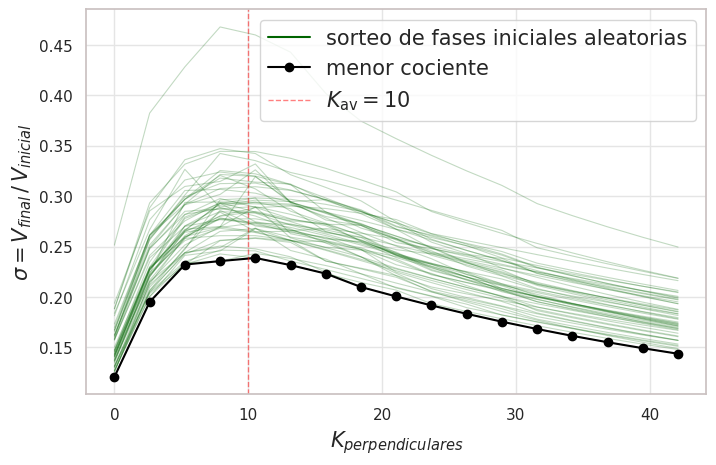

In [ ]:
from scipy.sparse import csr_matrix, identity, kron

BARRIDO = True    # False para saltear el barrido

if BARRIDO:
    N_K    = 20      # cuántos valores de K_perpendiculares
    N_CI   = 50      # condiciones iniciales por cada valor
    T_MAX  = 300     # tiempo máximo por simulación
    TOL    = 1e-6    # se considera convergido cuando max|dphi/dt| < TOL
    K_AV   = 10      # peso de avenidas y calles paralelas
    KP_MIN = 0.0     # primer K_perp del barrido (si falla en 0, poné 0.1)
    KP_MAX = 5*K_AV  # último K_perp del barrido
    DESCARTAR = 3    # cuántos de los últimos K no se grafican (0 = graficar todos)

    m = 10
    n = 3 * m
    A = matriz_ady1(m)
    Delta = np.full((n, n), 2 * np.pi / 8)
    d = A[0].sum()

    # las N_CI condiciones iniciales de un mismo K se integran juntas: una fila por sorteo (semilla b)
    PHI0 = np.array([condiciones_iniciales_random(n, semilla=b) for b in range(N_CI)])      # (N_CI, n)

    # cada sorteo solo depende de sí mismo: el jacobiano es por bloques (y de la forma de A), lo que acelera el integrador
    patron = kron(identity(N_CI), csr_matrix(A + np.eye(n)), format="csr")

    def pesos_trig(K):
        # las mismas ecuaciones, reescritas con senos y cosenos de cada fase para usar solo productos de matrices
        W1 = A * (0.5*K.T*np.cos(Delta.T) + 0.5*K*np.cos(Delta))
        W2 = A * (-0.5*K.T*np.sin(Delta.T) + 0.5*K*np.sin(Delta))
        return W1.T, W2.T

    def rhs_lote(t, y, W1T, W2T):
        s, c = np.sin(y.reshape(N_CI, n)), np.cos(y.reshape(N_CI, n))
        return ((c*(s @ W1T + c @ W2T) + s*(s @ W2T - c @ W1T)) / d).ravel()

    def convergio(t, y, W1T, W2T):                               # corta cuando todos los sorteos llegaron a un mínimo
        return np.abs(rhs_lote(t, y, W1T, W2T)).max() - TOL
    convergio.terminal = True

    def V_lote(phi, K):                                          # V de cada sorteo (fila de phi)
        D = phi[:, None, :] - phi[:, :, None]                    # D[b,i,j] = phi_j - phi_i
        return ((A*0.5*K.T) * (1 - np.cos(D - Delta.T))).sum(axis=(1, 2)) / d

    # --- barrido ---
    kps = np.linspace(KP_MIN, KP_MAX, N_K)
    Vfin = np.zeros((N_K, N_CI))
    V0 = np.zeros((N_K, N_CI))
    sin_converger = 0

    for a, kp in enumerate(kps):
        K = matriz_K1(m, K_AV, kp)
        W1T, W2T = pesos_trig(K)
        sol = solve_ivp(rhs_lote, (0, T_MAX), PHI0.ravel(), method="BDF", args=(W1T, W2T),
                        events=convergio, jac_sparsity=patron, rtol=1e-6, atol=1e-8)
        phi_fin = sol.y[:, -1].reshape(N_CI, n)
        Vfin[a] = V_lote(phi_fin, K)
        V0[a] = V_lote(PHI0, K)
        if sol.status != 1:                                      # no se llegó al mínimo en T_MAX
            sin_converger += (np.abs(rhs_lote(0, sol.y[:, -1], W1T, W2T).reshape(N_CI, n)).max(axis=1) > TOL).sum()

    print("simulaciones que no llegaron a un mínimo en T_MAX:", sin_converger)

    # --- gráfico: V final / V inicial, sin los últimos K ---
    sl = slice(0, N_K - DESCARTAR)
    cociente = Vfin / V0


plt.figure(figsize=(8, 5))
plt.plot(kps[sl], cociente[sl], color="darkgreen", lw=0.8,  alpha = 0.24)
plt.plot([], [], color="darkgreen", label="sorteo de fases iniciales aleatorias")
plt.plot(kps[sl], cociente[sl].min(axis=1), "o-", color="black", label="menor cociente")
plt.axvline(10, color="red", linestyle="--", linewidth=1, alpha=0.5, label= r"$K_\text{av} = 10$")
plt.xlabel(r"$K_{perpendiculares}$", fontsize = 15)
plt.ylabel(r"$\sigma = V_{final}\,/\,V_{inicial}$", fontsize = 15)
plt.legend(fontsize = 15)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

from google.colab import drive
drive.mount('/content/drive')

VV2024_semanal = pd.read_csv('/content/drive/MyDrive/labo/volumen_vehicular_2024_detalle_semanal.csv')

Mounted at /content/drive


In [ ]:
circuito = {
    'ENTRE RIOS AV. 678':     'norte',
    'BELGRANO AV. 324':       'este',
    'PASEO COLON AV. 753':    'sur',
    'INDEPENDENCIA AV. 1784': 'oeste',
}
dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

VV_8am = VV2024_semanal[
    (VV2024_semanal['ubicacion_conteo'].map(circuito) == VV2024_semanal['sentido_circulacion_conteo']) &
    (VV2024_semanal['franja_horaria_conteo'] == 8) &
    VV2024_semanal['dia_semana_conteo'].isin(dias)
].copy()

In [ ]:
por_dia = (VV_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())
prom_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))

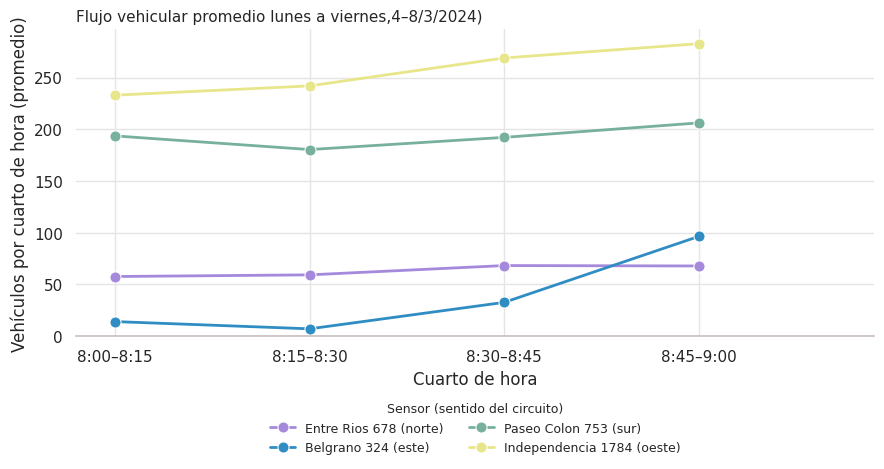

          ubicacion_conteo sentido_circulacion_conteo  cuarto_hora_conteo  \
0         BELGRANO AV. 324                       este                   1   
1         BELGRANO AV. 324                       este                   2   
2         BELGRANO AV. 324                       este                   3   
3         BELGRANO AV. 324                       este                   4   
4       ENTRE RIOS AV. 678                      norte                   1   
5       ENTRE RIOS AV. 678                      norte                   2   
6       ENTRE RIOS AV. 678                      norte                   3   
7       ENTRE RIOS AV. 678                      norte                   4   
8   INDEPENDENCIA AV. 1784                      oeste                   1   
9   INDEPENDENCIA AV. 1784                      oeste                   2   
10  INDEPENDENCIA AV. 1784                      oeste                   3   
11  INDEPENDENCIA AV. 1784                      oeste                   4   

In [ ]:
# etiquetas legibles
cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_8am['cuarto'] = prom_8am['cuarto_hora_conteo'].map(cuartos)
prom_8am['sensor'] = (prom_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title()+ ' (' + prom_8am['sentido_circulacion_conteo'] + ')')

orden = ['Entre Rios 678 (norte)', 'Belgrano 324 (este)', 'Paseo Colon 753 (sur)', 'Independencia 1784 (oeste)']
colores = dict(zip(orden, ["#a589db", "#2f8dc3", "#77b09c", "#e8e68a"]))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_8am.loc[(prom_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Flujo vehicular promedio lunes a viernes,4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(prom_8am)

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

from google.colab import drive
drive.mount('/content/drive')

circuito = pd.read_csv('/content/drive/MyDrive/labo/semaforos_circuito_distancias.csv')

Entre_Ríos = circuito[circuito['calle_recorrido'] == 'Av. Entre Ríos']
Belgrano = circuito[circuito['calle_recorrido'] == 'Av. Belgrano']
Paseo_Colón = circuito[circuito['calle_recorrido'] == 'Av. Paseo Colón']
Independencia = circuito[circuito['calle_recorrido'] == 'Av. Independencia']

print(Entre_Ríos)
print(Belgrano)
print(Paseo_Colón)
print(Independencia)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   orden calle_recorrido              cruce_con        lat        lon  \
0      1  Av. Entre Ríos  Avenida Independencia -34.618148 -58.391692   
1      2  Av. Entre Ríos                  Chile -34.616867 -58.391678   
2      3  Av. Entre Ríos                 México -34.615690 -58.391660   
3      4  Av. Entre Ríos              Venezuela -34.614899 -58.391677   

   distancia_desde_inicio_m  distancia_al_anterior_m  
0                         0                      NaN  
1                       121                    121.0  
2                       252                    131.0  
3                       340                     88.0  
    orden calle_recorrido                                          cruce_con  \
4       5    Av. Belgrano                                 Avenida Entre Ríos   
5       6    Av. Belgrano                                             

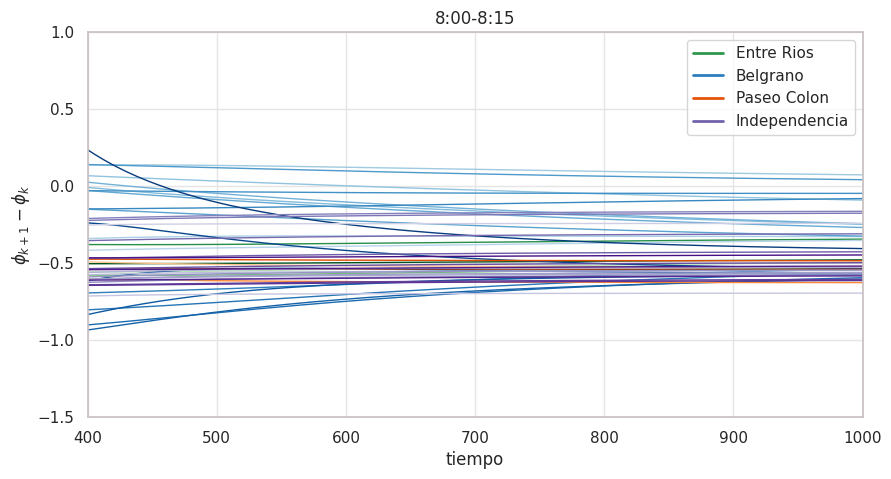

IndexError: index 45 is out of bounds for axis 1 with size 45

In [ ]:
#################################################################
############  circuito: Entre Ríos -> Belgrano -> Paseo Colón -> Independencia

from matplotlib.lines import Line2D

# --- supuestos míos, cambialos si tenés los reales ---
T_CICLO = 90.0     # s, ciclo común de todos los semáforos
V_KMH   = 60.0     # km/h, velocidad de marcha
T_SIM   = 1000     # tiempo de simulación

# --- distancia [m] del semáforo k al k+1 (el último cierra el circuito) ---
dist = np.array([121, 131, 88,                                                          # Entre Ríos
                 122, 125, 129, 43, 90, 132, 131, 132, 136, 36, 43, 37,
                 134, 131, 133, 134, 128, 129, 124,                                     # Belgrano
                 94, 125, 149, 115,                                                     # Paseo Colón
                 128, 57, 165, 130, 125, 135, 133, 129, 137, 38, 41, 73,
                 101, 118, 144, 146, 139, 124, 107])                                    # Independencia (el último vuelve al inicio)
n = len(dist)   # 45 semáforos: nodo k = orden k+1 de tu tabla

# calle por la que va cada tramo k -> k+1
calle = ["Entre Rios"]*4 + ["Belgrano"]*19 + ["Paseo Colon"]*4 + ["Independencia"]*18

# --- flujos [veh/15 min] de cada sensor, por cuarto de hora ---
flujos = {
    "8:00-8:15": {"Belgrano": 14.0, "Entre Rios": 57.6, "Independencia": 233.0, "Paseo Colon": 193.6},
    "8:15-8:30": {"Belgrano": 7.0,  "Entre Rios": 59.2, "Independencia": 242.0, "Paseo Colon": 180.4},
    "8:30-8:45": {"Belgrano": 32.6, "Entre Rios": 68.2, "Independencia": 269.0, "Paseo Colon": 192.2},
    "8:45-9:00": {"Belgrano": 96.4, "Entre Rios": 67.8, "Independencia": 282.8, "Paseo Colon": 206.2},
}

# --- matriz de adyacencia: anillo de 45 nodos ---
A = np.zeros((n, n))
for k in range(n):
    A[k, (k+1) % n] = 1
    A[(k+1) % n, k] = 1

# --- Delta = 2*pi*L/(T*v) entre semáforos consecutivos ---
v = V_KMH / 3.6
Delta = np.zeros((n, n))
for k in range(n):
    k2 = (k+1) % n
    Delta[k, k2] = Delta[k2, k] = (2*np.pi*dist[k]/(T_CICLO*v)) % (2*np.pi)

# --- matriz de pesos K: solo en el sentido de circulación (k -> k+1) ---
K_max = max(max(f.values()) for f in flujos.values())   # mismo escalado para los 4 casos

def matriz_K(f):
    K = np.zeros((n, n))
    for k in range(n):
        K[k, (k+1) % n] = f[calle[k]] / K_max
    return K

def wrap(x):
    return (x + np.pi) % (2*np.pi) - np.pi

colores_calle = {"Entre Rios":    plt.cm.Greens,
                 "Belgrano":      plt.cm.Blues,
                 "Paseo Colon":   plt.cm.Oranges,
                 "Independencia": plt.cm.Purples}

def potencial(phi, A, K, Delta):
    # V = sum_i (1/d) sum_{j vecino de i} (1/2) K_ji (1 - cos(phi_j - phi_i - Delta_ji))
    n = len(phi)                            # cantidad de nodos
    d = A[0].sum()                          # grado (es el mismo para todos)
    V = 0.0                                 # acumulador
    for i in range(n):                      # para cada nodo i
        for j in range(n):                  # mira todos los j
            if A[i, j] == 1:                # pero solo suma si j es vecino de i
                V += (1 / d) * 0.5 * K[j, i] * (1 - np.cos(phi[j] - phi[i] - Delta[j, i]))
    return V


def graficar_fases(t, y, titulo=""):
    n = len(y)
    fig, ax = plt.subplots(figsize=(10, 5))
    for nombre, cmap in colores_calle.items():
        ks = [k for k in range(n) if calle[k] == nombre]    # tramos de la avenida, en orden
        tonos = np.linspace(0.3, 0.95, len(ks))              # claro -> oscuro
        for k, tono in zip(ks, tonos):
            d = y[(k+1) % n] - y[k]
            d = d - 2*np.pi*np.round(d[-1]/(2*np.pi))        # todas en el mismo ciclo de 2*pi
            ax.plot(t, d, color=cmap(tono), lw=1)
    ax.legend(handles=[Line2D([0], [0], color=c(0.7), lw=2, label=nom)
                       for nom, c in colores_calle.items()], loc="upper right")
    ax.set_xlabel("tiempo")
    ax.set_ylabel(r"$\phi_{k+1}-\phi_k$")
    ax.set_title(titulo)
    ax.set_xlim(400, 1000)
    ax.set_ylim(-1.5, 1)
    plt.show()

    V = np.array([potencial(sol.y[:, f], A, K, Delta) for f in range(len(sol.t))])
    plt.figure(figsize=(8, 3.5))
    plt.plot(sol.t, V)
    plt.xlabel("tiempo")
    plt.ylabel("V")
    plt.title(CUARTO)
    plt.show()


# --- simular los 4 casos ---
resultados = {}

for cuarto, f in flujos.items():
    K = matriz_K(f)
    phi0 = condiciones_iniciales_random(n, semilla=0)
    t, y = simular(phi0, A, K, Delta, T_SIM)
    resultados[cuarto] = dict(K=K, t=t, y=y)


# --- graficar los 4 casos ---
for cuarto, r in resultados.items():
    graficar_fases(r["t"], r["y"], cuarto)




'''# offset logrado menos offset objetivo en cada tramo
    err = np.array([wrap(phi_f[k] - phi_f[(k+1) % n] - Delta[k, (k+1) % n]) for k in range(n)])
    vel = np.abs(ecuaciones(0, phi_f, A, K, Delta)).max()   # ~0 si convergió
    resultados[cuarto] = dict(K=K, t=t, y=y, err=err)
    print(cuarto, "| max|dphi/dt| = %.1e" % vel,
          "| error medio = %.3f rad" % np.abs(err).mean(),
          "| error max = %.3f rad" % np.abs(err).max())'''

In [ ]:
import matplotlib.animation as animation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 100      # MB, si no corta la animación

#################################################################
############  animación del circuito

CUARTO   = "8:00-8:15"   # qué caso de flujo usar
T_ANIM   = 1200          # s simulados
DT_FRAME = 3             # s entre cuadros
SEMILLA  = 0             # None = otra condición inicial cada vez
VERDE    = 0.5           # fracción del ciclo en verde

# --- posición de cada semáforo (lat, lon de tu tabla, orden 1..45) ---
latlon = np.array([
    [-34.618148, -58.391692], [-34.616867, -58.391678], [-34.615690, -58.391660], [-34.614899, -58.391677],
    [-34.613808, -58.391723], [-34.613716, -58.390365], [-34.613619, -58.388961], [-34.613587, -58.388498],
    [-34.613524, -58.387521], [-34.613428, -58.386082], [-34.613319, -58.384657], [-34.613211, -58.383226],
    [-34.613119, -58.381747], [-34.613090, -58.381360], [-34.613056, -58.380892], [-34.613030, -58.380487],
    [-34.612938, -58.379030], [-34.612870, -58.377605], [-34.612754, -58.376163], [-34.612645, -58.374707],
    [-34.612536, -58.373318], [-34.612452, -58.371918], [-34.612373, -58.370567], [-34.612328, -58.369547],
    [-34.613443, -58.369333], [-34.614782, -58.369468], [-34.615818, -58.369460], [-34.616965, -58.369434],
    [-34.617143, -58.369870], [-34.617187, -58.371673], [-34.617165, -58.373087], [-34.617243, -58.374450],
    [-34.617346, -58.375918], [-34.617445, -58.377367], [-34.617536, -58.378776], [-34.617628, -58.380264],
    [-34.617627, -58.380676], [-34.617635, -58.381128], [-34.617659, -58.381921], [-34.617727, -58.383019],
    [-34.617779, -58.384310], [-34.617837, -58.385875], [-34.617899, -58.387467], [-34.617993, -58.388978],
    [-34.618072, -58.390332]])
lat0, lon0 = latlon[:, 0].mean(), latlon[:, 1].mean()
px = (latlon[:, 1] - lon0) * 111320 * np.cos(np.radians(lat0))    # metros
py = (latlon[:, 0] - lat0) * 110540

# --- simular desde una condición inicial arbitraria ---
K = matriz_K(flujos[CUARTO])
phi0 = condiciones_iniciales_random(n, SEMILLA)
t_frames = np.arange(0, T_ANIM, DT_FRAME)
sol = solve_ivp(ecuaciones, (0, T_ANIM), phi0, args=(A, K, Delta, 0.0),
                t_eval=t_frames, rtol=1e-8, atol=1e-10)

# la simulación está en el sistema que rota con omega; para ver los semáforos se la devuelvo
omega = 2*np.pi/T_CICLO
fase_real = sol.y + omega*sol.t
verde = (fase_real % (2*np.pi)) < VERDE*2*np.pi      # True = verde, False = rojo

# --- dibujo ---
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(np.append(px, px[0]), np.append(py, py[0]), color="lightgray", lw=3, zorder=1)
sc = ax.scatter(px, py, s=80, edgecolor="black", zorder=2)
ax.set_aspect("equal")
ax.axis("off")
titulo = ax.set_title("")

def actualizar(f):
    sc.set_facecolor(list(np.where(verde[:, f], "limegreen", "red")))
    titulo.set_text(f"{CUARTO}  |  t = {sol.t[f]:.0f} s")
    return sc, titulo

anim = animation.FuncAnimation(fig, actualizar, frames=len(sol.t), interval=40, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn.objects as so

from google.colab import drive
drive.mount('/content/drive')

onda = pd.read_csv('/content/drive/MyDrive/labo/volumen_vehicular_2024_detalle_semanal.csv')
onda.head()

cordoba = onda[onda['ubicacion_conteo'] == 'CORDOBA AV. 4471']

circuito = {
    'CORDOBA AV. 1147':    'oeste',
    'CORDOBA AV. 1431':    'oeste',
    'CORDOBA AV. 1749':    'oeste',
    'CORDOBA AV. 1980':    'oeste',

    'CORDOBA AV. 2149':    'oeste',
    'CORDOBA AV. 2523':    'oeste',
    'CORDOBA AV. 2801':    'oeste',

    'CORDOBA AV. 3143':    'oeste',
    'CORDOBA AV. 3329':    'oeste',
    'CORDOBA AV. 3647':    'oeste',

    'CORDOBA AV. 4471':    'oeste',
    'CORDOBA AV. 4570':    'oeste',
}

dias = ['VIE', 'LUN', 'MAR', 'MIE', 'JUE']

onda_8am = onda[
    (onda['ubicacion_conteo'].map(circuito) == onda['sentido_circulacion_conteo']) &
    (onda['franja_horaria_conteo'] == 8) &
    onda['dia_semana_conteo'].isin(dias)
].copy()

por_dia = (onda_8am.groupby(['ubicacion_conteo', 'fecha_conteo','sentido_circulacion_conteo','cuarto_hora_conteo'])['conteo_vehiculos'].sum())

prom_onda_8am = (por_dia.groupby(['ubicacion_conteo','sentido_circulacion_conteo', 'cuarto_hora_conteo']).mean().reset_index(name='vehiculos_promedio'))

cuartos = {1: '8:00–8:15', 2: '8:15–8:30', 3: '8:30–8:45', 4: '8:45–9:00'}
prom_onda_8am['cuarto'] = prom_onda_8am['cuarto_hora_conteo'].map(cuartos)
prom_onda_8am['sensor'] = (prom_onda_8am['ubicacion_conteo'].str.replace(' AV.', '', regex=False).str.title() + ' (' + prom_onda_8am['sentido_circulacion_conteo'] + ')')

orden = ['Cordoba 1147 (oeste)', 'Cordoba 1431 (oeste)', 'Cordoba 1749 (oeste)', 'Cordoba 1980 (oeste)', 'Cordoba 2149 (oeste)','Cordoba 2523 (oeste)','Cordoba 2801 (oeste)', 'Cordoba 3143 (oeste)', 'Cordoba 3329 (oeste)', 'Cordoba 3647 (oeste)', 'Cordoba 4471 (oeste)', 'Cordoba 4570 (oeste)']

colores = dict(zip(orden, sns.color_palette('tab20', len(orden))))

sns.set_theme(style='whitegrid', rc={'grid.color': '#e5e5e5', 'axes.edgecolor': "#cac1c1"})
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=prom_onda_8am, x='cuarto', y='vehiculos_promedio', hue='sensor', hue_order=orden, palette=colores, marker='o', markersize=8, linewidth=2, sort=False, ax=ax)

for s in orden:
    y = prom_onda_8am.loc[(prom_onda_8am['cuarto_hora_conteo'] ==4), 'vehiculos_promedio'].iloc[0]

ax.set_title('Volumen vehicular promedio 4–8/3/2024)', loc='left', fontsize=11)
ax.set_xlabel('Cuarto de hora')
ax.set_ylabel('Vehículos por cuarto de hora (promedio)')
ax.set_ylim(0, None)
ax.set_xlim(-0.2, 3.9)
ax.legend(title='Sensor (sentido del circuito)', frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9, title_fontsize=9)
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(prom_onda_8am)


In [ ]:
semaforos_onda = pd.read_csv('/content/drive/MyDrive/labo/semaforos_cordoba_oeste.csv')
semaforos_onda

In [ ]:
#################################################################
############  Av. Córdoba (recta abierta, sentido oeste): datos y armado del modelo

# --- supuestos míos, cambialos si tenés los reales ---
T_CICLO = 90.0        # s, ciclo común de todos los semáforos
V_KMH   = 30.0        # km/h, velocidad de marcha
CUARTO  = 0           # 0 = 8:00-8:15, 1 = 8:15-8:30, 2 = 8:30-8:45, 3 = 8:45-9:00
QUITAR_ULTIMOS = 2    # cuántos semáforos del final se sacan (los 2 últimos son los de flujo ~600)

# --- semáforos (orden 1..35, sentido oeste): cruce y distancia [m] desde el inicio ---
cruces = ["Libertad", "Talcahuano", "Uruguay", "Paraná", "Montevideo", "Rodríguez Peña", "Callao Av.",
          "Riobamba", "Ayacucho", "Junín", "Uriburu José E. Pte.", "Pasteur", "Azcuénaga", "Larrea", "Paso",
          "Pueyrredón Av.", "Boulogne Sur Mer", "Ecuador", "Jean Jaures", "Anchorena T. de Dr.", "Agüero",
          "Gallo", "Sánchez de Bustamante", "Billinghurst", "Bravo Mario", "Bulnes", "Salguero Jerónimo",
          "Medrano Av.", "Acuña de Figueroa F.", "Gascón", "Palestina (ex Rawson)", "Pringles", "Lavalleja",
          "Alvarez Julián", "Araoz"]
pos = np.array([75.2, 206.0, 329.5, 455.7, 596.3, 768.5, 895.9, 1031.1, 1161.8, 1288.9,
                1435.4, 1539.6, 1645.9, 1780.8, 1848.5, 1922.2, 2023.3, 2105.0, 2197.3, 2340.6,
                2533.7, 2684.5, 2806.9, 2933.9, 3059.1, 3175.8, 3331.1, 3445.7, 3590.5, 3737.5,
                3888.5, 4032.5, 4116.2, 4238.4, 4361.4])

# --- sensores: dirección (número de calle) -> flujo [veh/15 min] en los 4 cuartos de hora ---
sensores = {1147: [25.0, 28.0, 27.2, 39.0],
            1431: [78.6, 75.6, 80.8, 93.0],
            1749: [14.8, 18.0, 37.4, 44.8],
            1980: [286.2, 284.8, 292.0, 329.6],
            2149: [76.8, 120.2, 140.0, 142.6],
            2523: [26.0, 72.6, 73.0, 69.6],
            2801: [92.4, 124.8, 141.4, 147.0],
            3143: [26.4, 36.0, 31.2, 33.6],
            3329: [125.2, 125.0, 143.0, 163.2],
            3647: [134.6, 136.6, 154.2, 157.2],
            4471: [661.333333, 633.333333, 626.333333, 639.0],
            4570: [696.0, 670.8, 672.2, 663.8]}

# posición de cada sensor sobre la avenida: el primero y el último van en el primer y último
# semáforo, y los del medio proporcionales al número de calle (esto se hace con los 35 semáforos)
direc = np.array(list(sensores.keys()))
pos_sensor = pos[0] + (direc - direc[0]) / (direc[-1] - direc[0]) * (pos[-1] - pos[0])
flujo_sensor = np.array([f[CUARTO] for f in sensores.values()])

# --- sacar los últimos semáforos y los sensores que quedan más allá ---
if QUITAR_ULTIMOS > 0:
    pos, cruces = pos[:-QUITAR_ULTIMOS], cruces[:-QUITAR_ULTIMOS]
dentro = pos_sensor <= pos[-1]
pos_sensor, flujo_sensor = pos_sensor[dentro], flujo_sensor[dentro]

n = len(pos)
dist = np.diff(pos)                                   # tramos: semáforo k -> k+1
print(f"{n} semáforos: de {cruces[0]} a {cruces[-1]} | {dentro.sum()} sensores usados")

# flujo de cada tramo: interpolado entre sensores, en el punto medio del tramo
# (después del último sensor queda constante)
medio = (pos[:-1] + pos[1:]) / 2
flujo_tramo = np.interp(medio, pos_sensor, flujo_sensor)

# --- adyacencia: recta de n nodos (no se cierra) ---
A = np.zeros((n, n))
for k in range(n - 1):
    A[k, k+1] = A[k+1, k] = 1

# --- Delta = 2*pi*L/(T*v) entre semáforos consecutivos ---
v = V_KMH / 3.6
Delta = np.zeros((n, n))
for k in range(n - 1):
    Delta[k, k+1] = Delta[k+1, k] = (2*np.pi*dist[k]/(T_CICLO*v)) % (2*np.pi)

# --- pesos K: solo en el sentido de circulación (k -> k+1, hacia el oeste) ---
K = np.zeros((n, n))
for k in range(n - 1):
    K[k, k+1] = flujo_tramo[k] / flujo_tramo.max()

33 semáforos: de Libertad a Lavalleja | 10 sensores usados


Corriendo 30 simulaciones para Av. Córdoba...


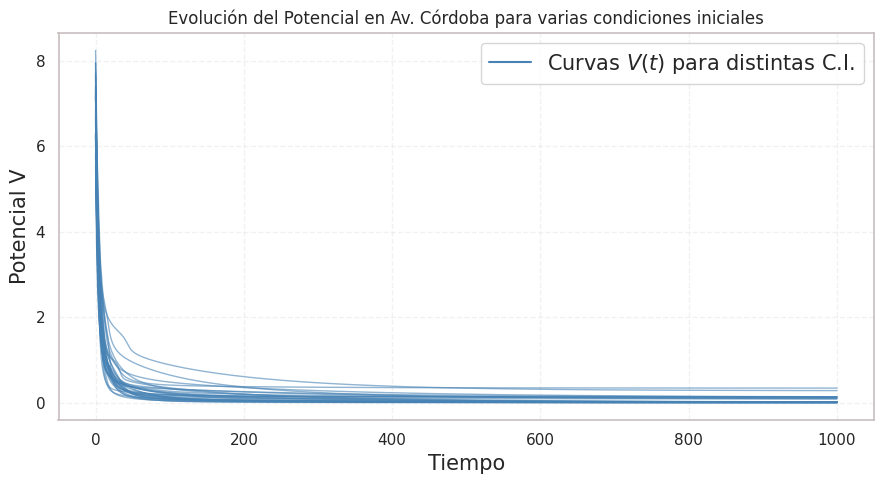

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# A. Avenida Córdoba: Múltiples Condiciones Iniciales (Escala Lineal y Optimizado)
# =============================================================================

T_SIM = 1000
N_CI_cordoba = 30  # Cantidad de condiciones iniciales a probar

plt.figure(figsize=(9, 5))
print(f"Corriendo {N_CI_cordoba} simulaciones para Av. Córdoba...")

# Función para calcular el potencial vectorizado en el tiempo
# Esto elimina el "for" de Python y calcula toda la trayectoria de un solo golpe
def potencial_vectorizado(phi_trayectoria, A, K, Delta):
    # phi_trayectoria tiene forma (n_nodos, n_tiempos)
    # Agregamos ejes para hacer broadcasting y obtener D de forma (n, n, n_tiempos)
    D = phi_trayectoria[None, :, :] - phi_trayectoria[:, None, :]

    # Adaptamos las matrices A, K y Delta agregándoles el eje de tiempo al final
    A_ext = A[:, :, None]
    K_ext = K.T[:, :, None]
    Delta_ext = Delta.T[:, :, None]

    d = A[0].sum()

    # Calculamos todo y sumamos sobre las filas y columnas de la red (ejes 0 y 1)
    # El resultado es un vector 1D con el potencial para cada instante de tiempo
    V_todos_los_tiempos = (A_ext * 0.5 * K_ext * (1 - np.cos(D - Delta_ext))).sum(axis=(0, 1)) / d
    return V_todos_los_tiempos

for b in range(N_CI_cordoba):
    # Generamos CI aleatorias
    phi0_cordoba = condiciones_iniciales_random(n, semilla=b)

    # Integramos usando tu función 'simular'
    t_c, phi_c = simular(phi0_cordoba, A, K, Delta, T_SIM)

    # Calculamos el potencial V(t) para TODA la trayectoria de una (ultra rápido)
    V_c = potencial_vectorizado(phi_c, A, K, Delta)

    # Ploteamos esta trayectoria (ya sin escala log)
    plt.plot(t_c, V_c, color="steelblue", lw=1.0, alpha=0.6)

# Truco para la leyenda
plt.plot([], [], color="steelblue", label=r"Curvas $V(t)$ para distintas C.I.")

# Ejes en escala lineal (se eliminaron symlog y log)
plt.xlabel("Tiempo", fontsize = 15)
plt.ylabel("Potencial V", fontsize = 15)
plt.title("Evolución del Potencial en Av. Córdoba para varias condiciones iniciales")
plt.legend(fontsize = 15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

v = 20 km/h: corriendo 30 simulaciones...
v = 30 km/h: corriendo 30 simulaciones...
v = 40 km/h: corriendo 30 simulaciones...
v = 50 km/h: corriendo 30 simulaciones...
v = 60 km/h: corriendo 30 simulaciones...


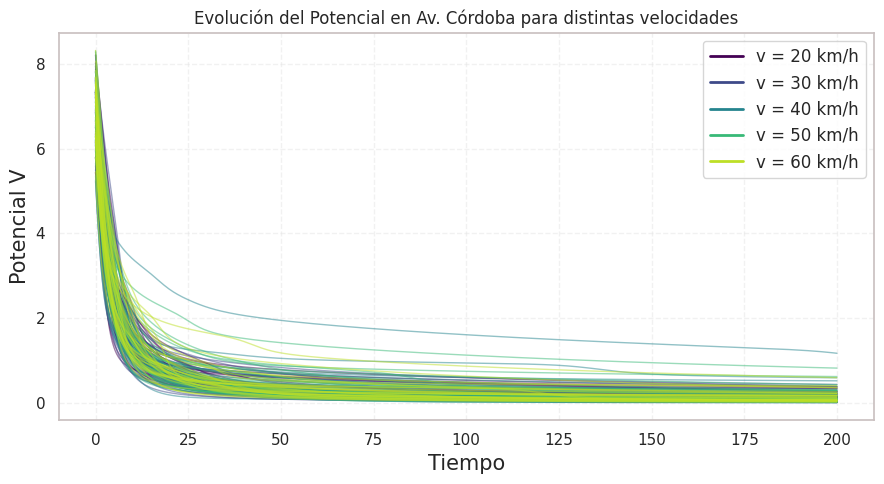

In [ ]:
##### BARRIDO DE VELOCIDADES

# =============================================================================
# B. Barrido de velocidad: V(t) para varias C.I., todas las velocidades en un mismo gráfico
# =============================================================================

BARRER_V = True
velocidades_kmh = [20, 30, 40, 50, 60]   # km/h
colores = plt.cm.viridis(np.linspace(0, 0.9, len(velocidades_kmh)))   # gradiente, un color por v

if BARRER_V:
    plt.figure(figsize=(9, 5))

    for i in range(len(velocidades_kmh)):
        v_kmh = velocidades_kmh[i]
        # Delta depende de la velocidad; A y K no cambian
        v_ms = v_kmh / 3.6
        Delta_v = np.zeros((n, n))
        for k in range(n - 1):
            Delta_v[k, k+1] = Delta_v[k+1, k] = (2*np.pi*dist[k]/(T_CICLO*v_ms)) % (2*np.pi)

        print(f"v = {v_kmh} km/h: corriendo {N_CI_cordoba} simulaciones...")

        for b in range(N_CI_cordoba):
            phi0_cordoba = condiciones_iniciales_random(n, semilla=b)   # mismas semillas en cada v
            t_c, phi_c = simular(phi0_cordoba, A, K, Delta_v, T_SIM)
            V_c = potencial_vectorizado(phi_c, A, K, Delta_v)
            plt.plot(t_c, V_c, color=colores[i], lw=1.0, alpha=0.5)

        plt.plot([], [], color=colores[i], lw=2, label=f"v = {v_kmh} km/h")   # una entrada por velocidad

    plt.xlabel("Tiempo", fontsize=15)
    plt.ylabel("Potencial V", fontsize=15)
    plt.title("Evolución del Potencial en Av. Córdoba para distintas velocidades")
    plt.legend(fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()